# PCA

## Manual Method: Eigen decomposition of the covariance matrix

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

In [2]:
# Step 1: Create a simple 3D dataset
# Assume we have 3D data points (X, Y, Z)
np.random.seed(0)
X = np.array([[2.5, 2.4, 3.1],
              [0.5, 0.7, 0.8],
              [2.2, 2.9, 2.7],
              [1.9, 2.2, 3.0],
              [3.1, 3.0, 3.4],
              [2.3, 2.7, 3.3],
              [2.0, 1.6, 2.9],
              [1.0, 1.1, 1.4],
              [1.5, 1.6, 1.7],
              [1.1, 0.9, 1.3]])
X

array([[2.5, 2.4, 3.1],
       [0.5, 0.7, 0.8],
       [2.2, 2.9, 2.7],
       [1.9, 2.2, 3. ],
       [3.1, 3. , 3.4],
       [2.3, 2.7, 3.3],
       [2. , 1.6, 2.9],
       [1. , 1.1, 1.4],
       [1.5, 1.6, 1.7],
       [1.1, 0.9, 1.3]])

In [3]:
# Step 2: Center the data
mean_X = np.mean(X, axis=0)
centered_X = X - mean_X
centered_X

array([[ 0.69,  0.49,  0.74],
       [-1.31, -1.21, -1.56],
       [ 0.39,  0.99,  0.34],
       [ 0.09,  0.29,  0.64],
       [ 1.29,  1.09,  1.04],
       [ 0.49,  0.79,  0.94],
       [ 0.19, -0.31,  0.54],
       [-0.81, -0.81, -0.96],
       [-0.31, -0.31, -0.66],
       [-0.71, -1.01, -1.06]])

In [6]:
# Step 3: Compute the covariance matrix
cov_matrix = np.cov(centered_X.T)
cov_matrix

array([[0.61655556, 0.61544444, 0.70933333],
       [0.61544444, 0.71655556, 0.726     ],
       [0.70933333, 0.726     , 0.916     ]])

In [7]:
# Step 4: Perform Eigen decomposition
eigenvalues, eigenvectors = np.linalg.eig(cov_matrix)
eigenvalues, eigenvectors

(array([2.13131399, 0.03425595, 0.08354118]),
 array([[ 0.52692233,  0.84922771,  0.03413439],
        [ 0.55813841, -0.31546248, -0.76744051],
        [ 0.64096363, -0.42343326,  0.64021083]]))

In [9]:
# Step 5: Sort eigenvalues and eigenvectors in descending order of eigenvalues
sorted_indices = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[sorted_indices]
eigenvectors = eigenvectors[:, sorted_indices]
eigenvalues, eigenvectors

(array([2.13131399, 0.08354118, 0.03425595]),
 array([[ 0.52692233,  0.03413439,  0.84922771],
        [ 0.55813841, -0.76744051, -0.31546248],
        [ 0.64096363,  0.64021083, -0.42343326]]))

In [11]:
# Step 6: Select the top k eigenvectors (for PCA to 2D, we select the first 2 eigenvectors)
k = 2
top_k_eigenvectors = eigenvectors[:, :k]
top_k_eigenvectors

array([[ 0.52692233,  0.03413439],
       [ 0.55813841, -0.76744051],
       [ 0.64096363,  0.64021083]])

In [12]:
# Step 7: Project the data onto the new 2D space
X_pca = np.dot(centered_X, top_k_eigenvectors)
X_pca

array([[ 1.11137731,  0.12126289],
       [-2.36551899, -0.11484192],
       [ 0.97598437, -0.52878201],
       [ 0.61949987,  0.19024928],
       [ 1.95470285, -0.12665754],
       [ 1.3016271 ,  0.01224602],
       [ 0.2732127 ,  0.59010594],
       [-1.49422428, -0.02062443],
       [-0.75940482, -0.19521425],
       [-1.61725609,  0.07225603]])

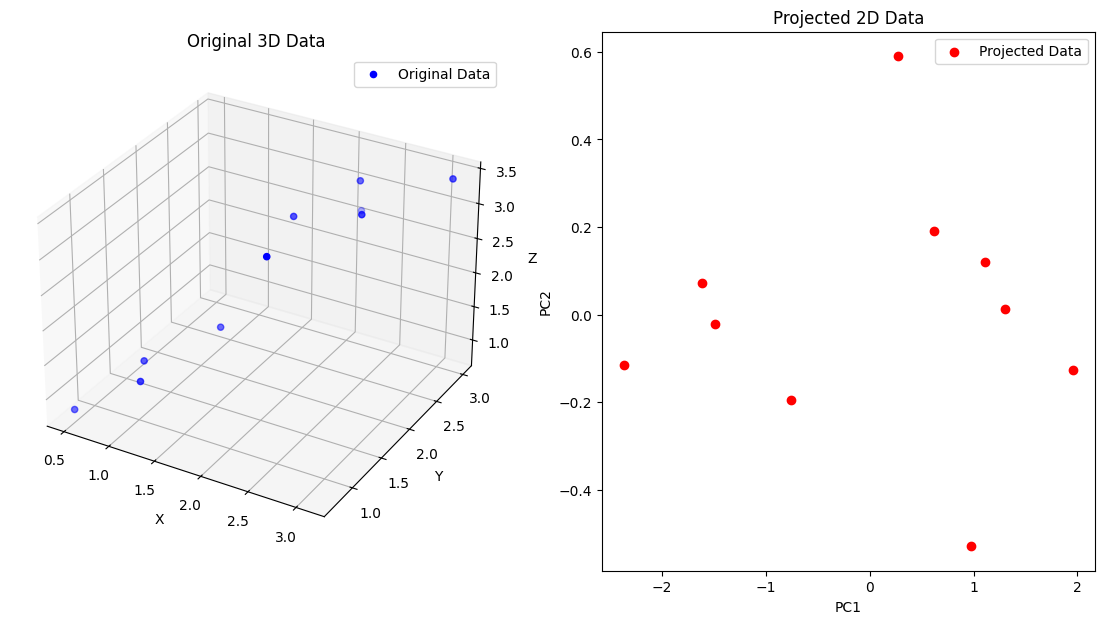

In [19]:
from re import A
# Step 8: Visualization of the original 3D data and its projection onto 2D

fig = plt.figure(figsize=(14, 7))

# Original 3D data visualization
ax1 = fig.add_subplot(1, 2, 1, projection='3d')
ax1.scatter(X[:, 0], X[:, 1], X[:, 2], c='b', marker='o', label='Original Data')
ax1.set_title('Original 3D Data')
ax1.set_xlabel('X')
ax1.set_ylabel('Y')
ax1.set_zlabel('Z')
ax1.legend()

# Projected 2D data visualization
ax2 = fig.add_subplot(1, 2, 2)
ax2.scatter(X_pca[:, 0], X_pca[:, 1], c='r', marker='o', label='Projected Data')
ax2.set_title('Projected 2D Data')
ax2.set_xlabel('PC1')
ax2.set_ylabel('PC2')
ax2.legend()

plt.show()




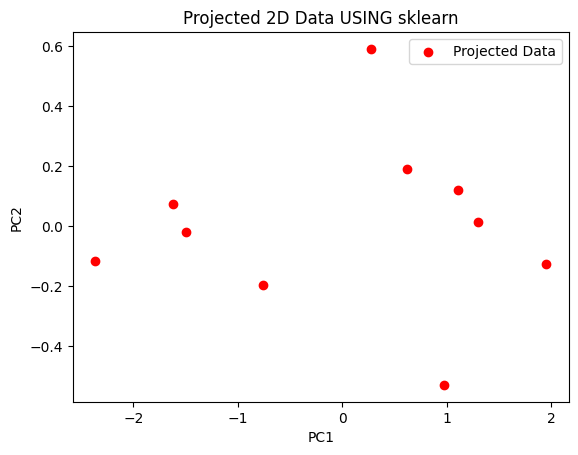

In [21]:
# Projected 2D data visualization
plt.scatter(X_pca[:, 0], X_pca[:, 1], c='r', marker='o', label='Projected Data')
plt.title('Projected 2D Data USING sklearn')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.show()

## Scikit-Learn PCA: Built-in PCA from Scikit-Learn, which internally uses SVD.

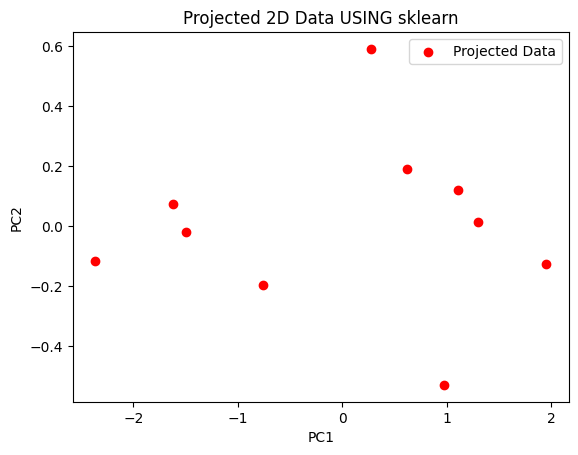

In [37]:
# Step 1: PCA with sklearn
pca = PCA(n_components=2)
# pca = PCA(n_components=0.95) # This is the percentage; can be used in both ways
X_pca_sklearn = pca.fit_transform(X)

plt.scatter(X_pca_sklearn[:, 0], -X_pca_sklearn[:, 1], c='r', marker='o', label='Projected Data')
plt.title('Projected 2D Data USING sklearn')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.legend()
plt.show()

In [38]:
# Step 2: Get the explained variance
explined_variation_ratio = pca.explained_variance_ratio_
explined_variation_ratio

array([0.94762503, 0.03714409])

In [39]:
cummulative_variance = np.cumsum(explined_variation_ratio)
cummulative_variance

array([0.94762503, 0.98476912])

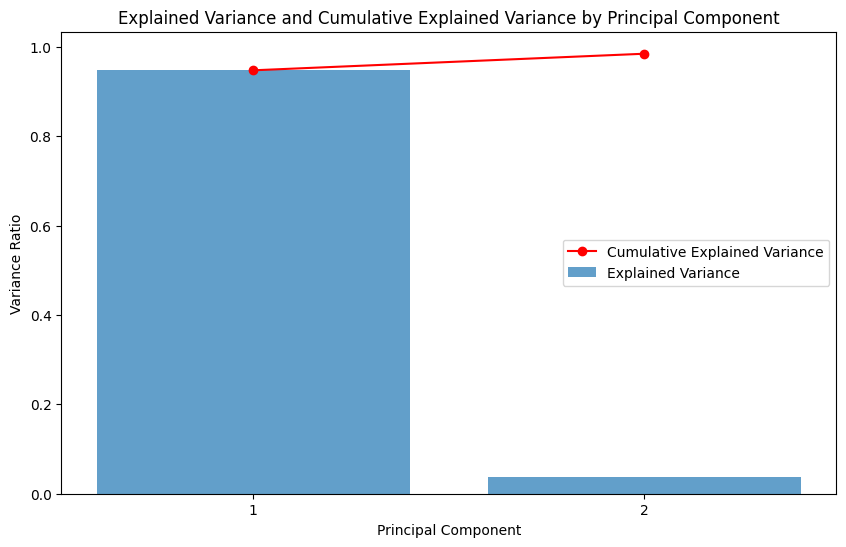

In [40]:
# Step 3: Plot the explained variance for each component
plt.figure(figsize=(10, 6))

# Plot the explained variance ratio for each component
plt.bar(range(1, len(explined_variation_ratio) + 1), explined_variation_ratio, alpha=0.7, label='Explained Variance')

# Plot the cumulative explained variance
plt.plot(range(1, len(cummulative_variance) + 1), cummulative_variance, marker='o', color='red', label='Cumulative Explained Variance')

# Step 4: Add titles and labels
plt.title('Explained Variance and Cumulative Explained Variance by Principal Component')
plt.xlabel('Principal Component')
plt.ylabel('Variance Ratio')
plt.xticks(range(1, len(explined_variation_ratio) + 1))
plt.legend(loc='best')

# Show the plot
plt.show()